# Atividade I - Cálculo Numérico
## Erros numéricos em aplicações simples de biofluidodinâmica

**Aluno(a):** preencher  
**Turma:** preencher  
**Data:** preencher  
**Integrantes e divisão das tarefas:** preencher

Este notebook resolve a atividade prática sobre erros absoluto, relativo e percentual, truncamento, arredondamento, propagação de erros em vazão e efeitos numéricos em um modelo didático de nanocateter.

## Síntese

As aproximações por arredondamento tendem a produzir erros menores ou iguais aos do truncamento para a mesma quantidade de casas decimais, mas a vantagem depende do número analisado e da casa escolhida. Nas medidas de pressão, a representação inteira preserva razoavelmente a média da pequena amostra, mas altera a amplitude, o desvio-padrão e a distribuição. Na relação de Hagen-Poiseuille, a vazão depende de $r^4$, portanto pequenos erros no raio são amplificados aproximadamente por um fator 4 no erro relativo da vazão. No nanocateter, a precisão aritmética deve ser separada da validade física: muitas casas decimais não garantem que o modelo idealizado represente todos os efeitos relevantes em escala nanométrica.

## 1. Preparação do ambiente

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Image as IPythonImage

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.6e}' if abs(x) < 1e-3 and x != 0 else f'{x:,.6f}')

output_dir = Path('atividade_I_outputs')
output_dir.mkdir(exist_ok=True)

print('Ambiente preparado com sucesso.')

Ambiente preparado com sucesso.


## 2. Funções auxiliares

In [2]:
def truncar(numero, casas):
    """Trunca um número para uma quantidade fixa de casas decimais sem arredondar."""
    fator = 10 ** casas
    return math.trunc(numero * fator) / fator


def calcular_erros(referencia, aproximacao):
    """Calcula erro absoluto, relativo e percentual entre referência e aproximação."""
    erro_absoluto = abs(referencia - aproximacao)
    if referencia == 0:
        erro_relativo = np.nan
        erro_percentual = np.nan
    else:
        erro_relativo = erro_absoluto / abs(referencia)
        erro_percentual = 100 * erro_relativo
    return erro_absoluto, erro_relativo, erro_percentual


def vazao_hagen_poiseuille(raio_m, comprimento_m, viscosidade_pa_s, delta_p_pa):
    """Calcula Q = pi r^4 delta_p / (8 mu L), em m^3/s."""
    return math.pi * raio_m**4 * delta_p_pa / (8 * viscosidade_pa_s * comprimento_m)


def format_sci(valor, unidade=''):
    return f'{valor:.6e} {unidade}'.strip()

print('Funções auxiliares definidas.')

Funções auxiliares definidas.


## 3. Parte A - truncamento e arredondamento

In [3]:
valores_a = {
    'x1': 3.14159265,
    'x2': 98.76543,
    'x3': 0.00498765,
}
casas_decimais = list(range(0, 5))

linhas_a = []
for nome, referencia in valores_a.items():
    for n in casas_decimais:
        for metodo, aproximacao in [
            ('truncamento', truncar(referencia, n)),
            ('arredondamento', round(referencia, n)),
        ]:
            ea, er, ep = calcular_erros(referencia, aproximacao)
            linhas_a.append({
                'valor': nome,
                'referência': referencia,
                'n casas': n,
                'método': metodo,
                'aproximação': aproximacao,
                'Ea': ea,
                'Er': er,
                'E%': ep,
            })

tabela_a = pd.DataFrame(linhas_a)
display(tabela_a)

,valor,referência,n casas,método,aproximação,Ea,Er,E%
0,x1,3.141593,0,truncamento,3.000000,0.141593,0.045070,4.507034
1,x1,3.141593,0,arredondamento,3.000000,0.141593,0.045070,4.507034
2,x1,3.141593,1,truncamento,3.100000,0.041593,0.013239,1.323935
3,x1,3.141593,1,arredondamento,3.100000,0.041593,0.013239,1.323935
4,x1,3.141593,2,truncamento,3.140000,0.001593,5.069562e-04,0.050696
5,x1,3.141593,2,arredondamento,3.140000,0.001593,5.069562e-04,0.050696
6,x1,3.141593,3,truncamento,3.141000,5.926500e-04,1.886464e-04,0.018865
7,x1,3.141593,3,arredondamento,3.142000,4.073500e-04,1.296635e-04,0.012966
8,x1,3.141593,4,truncamento,3.141500,9.265000e-05,2.949141e-05,0.002949
9,x1,3.141593,4,arredondamento,3.141600,7.350000e-06,2.339578e-06,2.339578e-04


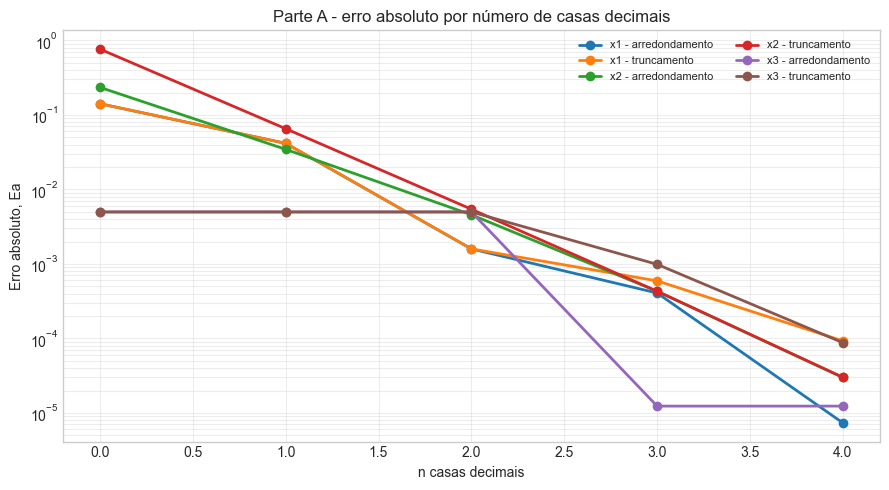

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for (nome, metodo), dados in tabela_a.groupby(['valor', 'método']):
    ax.plot(dados['n casas'], dados['Ea'], marker='o', linewidth=2, label=f'{nome} - {metodo}')
ax.set_yscale('log')
ax.set_title('Parte A - erro absoluto por número de casas decimais')
ax.set_xlabel('n casas decimais')
ax.set_ylabel('Erro absoluto, Ea')
ax.legend(ncol=2, fontsize=8)
ax.grid(True, which='both', alpha=0.35)
plt.tight_layout()
plt.show()

**Resposta - Parte A.** Arredondar geralmente gera erro menor ou igual ao truncamento porque escolhe o número representável mais próximo na casa decimal desejada, enquanto truncar apenas descarta os algarismos posteriores. Nos resultados, isso aparece de forma clara para $x_1$ e $x_2$ em várias casas decimais. Porém, pode haver empates quando as duas operações produzem a mesma aproximação ou quando a casa analisada não altera o valor de forma relevante. Portanto, arredondar não é magicamente isento de erro, mas costuma ser melhor que truncar para representar uma medida com número fixo de casas decimais.

## 4. Parte B - medidas de pressão arterial

In [5]:
pressao_original = np.array([121.7, 120.4, 122.1, 119.8, 121.2, 120.9, 122.4, 121.0, 120.2, 121.5])
media_referencia_pressao = pressao_original.mean()

series_pressao = {
    'originais': pressao_original,
    'arredondados inteiro': np.round(pressao_original, 0),
    'truncados inteiro': np.array([truncar(x, 0) for x in pressao_original]),
    'arredondados 1 casa': np.round(pressao_original, 1),
}

linhas_stats = []
linhas_erros_media = []
for nome, serie in series_pressao.items():
    media = serie.mean()
    linhas_stats.append({
        'série': nome,
        'média (mmHg)': media,
        'mínimo (mmHg)': serie.min(),
        'máximo (mmHg)': serie.max(),
        'amplitude (mmHg)': serie.max() - serie.min(),
        'desvio-padrão amostral (mmHg)': serie.std(ddof=1),
    })
    ea, er, ep = calcular_erros(media_referencia_pressao, media)
    linhas_erros_media.append({
        'série': nome,
        'média aproximada (mmHg)': media,
        'Ea da média (mmHg)': ea,
        'Er da média': er,
        'E% da média': ep,
    })

tabela_pressao_stats = pd.DataFrame(linhas_stats)
tabela_pressao_erros = pd.DataFrame(linhas_erros_media)

print(f'Média de referência: {media_referencia_pressao:.4f} mmHg')
display(tabela_pressao_stats)
display(tabela_pressao_erros)

Média de referência: 121.1200 mmHg


,série,média (mmHg),mínimo (mmHg),máximo (mmHg),amplitude (mmHg),desvio-padrão amostral (mmHg)
0,originais,121.120000,119.800000,122.400000,2.600000,0.833733
1,arredondados inteiro,121.100000,120.000000,122.000000,2.000000,0.875595
2,truncados inteiro,120.700000,119.000000,122.000000,3.000000,0.948683
3,arredondados 1 casa,121.120000,119.800000,122.400000,2.600000,0.833733


,série,média aproximada (mmHg),Ea da média (mmHg),Er da média,E% da média
0,originais,121.120000,0.000000,0.000000,0.000000
1,arredondados inteiro,121.100000,0.020000,1.651255e-04,0.016513
2,truncados inteiro,120.700000,0.420000,0.003468,0.346764
3,arredondados 1 casa,121.120000,0.000000,0.000000,0.000000


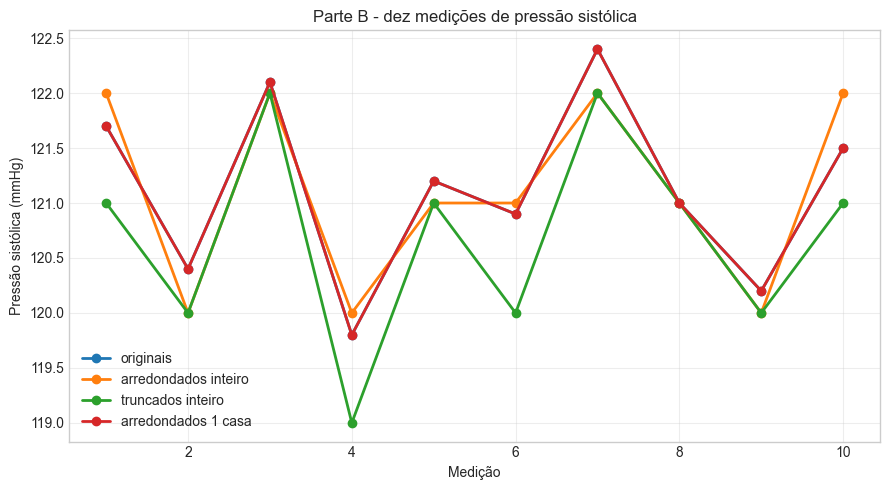

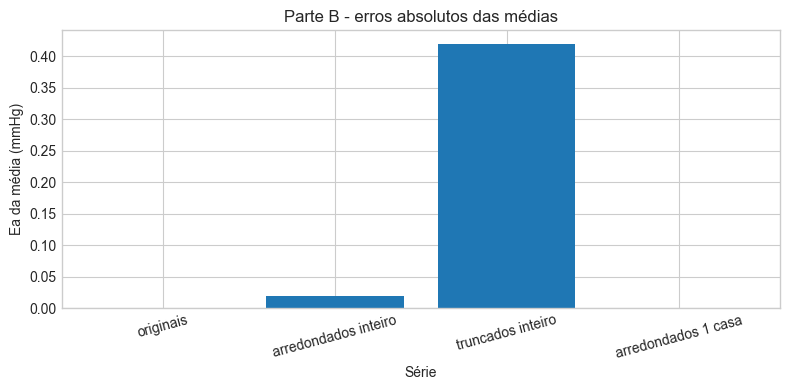

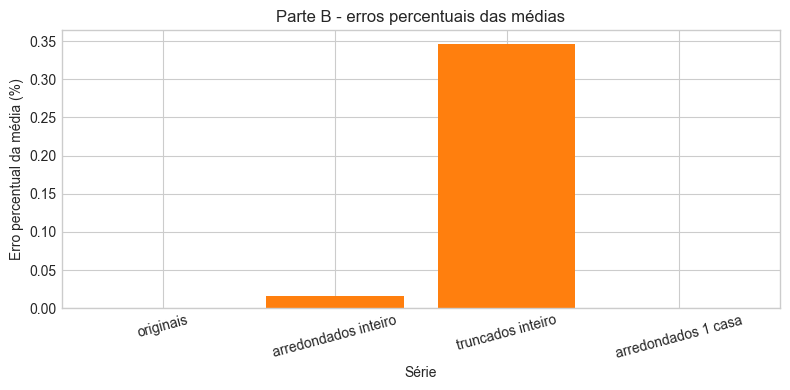

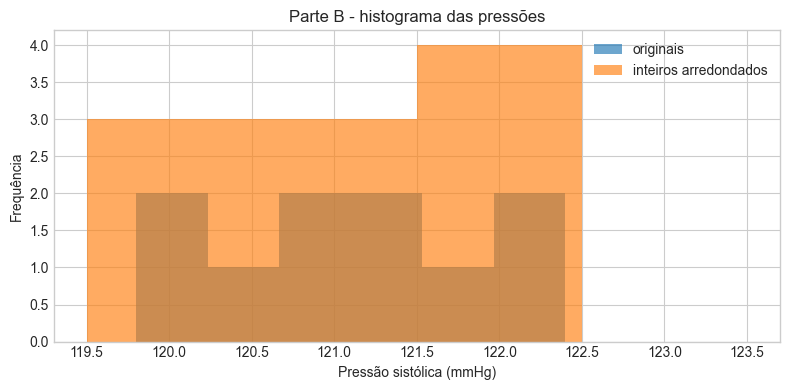

In [6]:
indices = np.arange(1, len(pressao_original) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
for nome, serie in series_pressao.items():
    ax.plot(indices, serie, marker='o', linewidth=2, label=nome)
ax.set_title('Parte B - dez medições de pressão sistólica')
ax.set_xlabel('Medição')
ax.set_ylabel('Pressão sistólica (mmHg)')
ax.legend()
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tabela_pressao_erros['série'], tabela_pressao_erros['Ea da média (mmHg)'], color='tab:blue')
ax.set_title('Parte B - erros absolutos das médias')
ax.set_xlabel('Série')
ax.set_ylabel('Ea da média (mmHg)')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tabela_pressao_erros['série'], tabela_pressao_erros['E% da média'], color='tab:orange')
ax.set_title('Parte B - erros percentuais das médias')
ax.set_xlabel('Série')
ax.set_ylabel('Erro percentual da média (%)')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pressao_original, bins=6, alpha=0.65, label='originais')
ax.hist(series_pressao['arredondados inteiro'], bins=np.arange(119.5, 123.6, 1), alpha=0.65, label='inteiros arredondados')
ax.set_title('Parte B - histograma das pressões')
ax.set_xlabel('Pressão sistólica (mmHg)')
ax.set_ylabel('Frequência')
ax.legend()
plt.tight_layout()
plt.show()

**Resposta - Parte B.** A representação inteira preserva razoavelmente a média desta pequena amostra, pois os erros percentuais das médias são baixos. Entretanto, ela reduz a informação decimal e altera a distribuição visual, a amplitude e o desvio-padrão. Assim, valores inteiros podem ser suficientes para uma visão aproximada da média, mas não preservam toda a variabilidade dos dados originais. Esta análise é apenas numérica e não faz interpretação médica dos valores.

## 5. Parte C - vazão em tubo de pequeno diâmetro

In [7]:
r_mm_c = 0.80
L_c = 0.20
mu_c = 3.5e-3
delta_p_c = 1200

r_m_c = r_mm_c * 1e-3
Q_ref_c = vazao_hagen_poiseuille(r_m_c, L_c, mu_c, delta_p_c)

cenarios_c = []

def adicionar_cenario(nome, r_mm, mu, delta_p):
    Q = vazao_hagen_poiseuille(r_mm * 1e-3, L_c, mu, delta_p)
    ea, er, ep = calcular_erros(Q_ref_c, Q)
    cenarios_c.append({
        'cenário': nome,
        'r usado (mm)': r_mm,
        'mu usado (Pa s)': mu,
        'Delta p usado (Pa)': delta_p,
        'Q (m³/s)': Q,
        'Q (uL/s)': Q * 1e9,
        'Ea de Q (m³/s)': ea,
        'Er de Q': er,
        'E% de Q': ep,
    })

adicionar_cenario('referência - todos os valores fornecidos', r_mm_c, mu_c, delta_p_c)
adicionar_cenario('r arredondado para 1 casa decimal', round(r_mm_c, 1), mu_c, delta_p_c)
adicionar_cenario('r truncado para 1 casa decimal', truncar(r_mm_c, 1), mu_c, delta_p_c)
adicionar_cenario('mu arredondada para 3 casas decimais', r_mm_c, round(mu_c, 3), delta_p_c)
adicionar_cenario('mu truncada para 3 casas decimais', r_mm_c, truncar(mu_c, 3), delta_p_c)
adicionar_cenario('Delta p arredondada para centenas', r_mm_c, mu_c, round(delta_p_c / 100) * 100)
adicionar_cenario('Delta p truncada para centenas', r_mm_c, mu_c, truncar(delta_p_c / 100, 0) * 100)
adicionar_cenario('todas arredondadas simultaneamente', round(r_mm_c, 1), round(mu_c, 3), round(delta_p_c / 100) * 100)
adicionar_cenario('todas truncadas simultaneamente', truncar(r_mm_c, 1), truncar(mu_c, 3), truncar(delta_p_c / 100, 0) * 100)

tabela_c = pd.DataFrame(cenarios_c)
display(tabela_c)
print(f'Q de referência = {Q_ref_c:.6e} m³/s = {Q_ref_c*1e9:.6f} uL/s')

,cenário,r usado (mm),mu usado (Pa s),Delta p usado (Pa),Q (m³/s),Q (uL/s),Ea de Q (m³/s),Er de Q,E% de Q
0,referência - todos os valores fornecidos,0.800000,0.003500,"1,200.000000",2.757421e-07,275.742075,0.000000,0.000000,0.000000
1,r arredondado para 1 casa decimal,0.800000,0.003500,"1,200.000000",2.757421e-07,275.742075,0.000000,0.000000,0.000000
2,r truncado para 1 casa decimal,0.800000,0.003500,"1,200.000000",2.757421e-07,275.742075,0.000000,0.000000,0.000000
3,mu arredondada para 3 casas decimais,0.800000,0.004000,"1,200.000000",2.412743e-07,241.274316,3.446776e-08,0.125000,12.500000
4,mu truncada para 3 casas decimais,0.800000,0.003000,"1,200.000000",3.216991e-07,321.699088,4.595701e-08,0.166667,16.666667
5,Delta p arredondada para centenas,0.800000,0.003500,"1,200.000000",2.757421e-07,275.742075,0.000000,0.000000,0.000000
6,Delta p truncada para centenas,0.800000,0.003500,"1,200.000000",2.757421e-07,275.742075,0.000000,0.000000,0.000000
7,todas arredondadas simultaneamente,0.800000,0.004000,"1,200.000000",2.412743e-07,241.274316,3.446776e-08,0.125000,12.500000
8,todas truncadas simultaneamente,0.800000,0.003000,"1,200.000000",3.216991e-07,321.699088,4.595701e-08,0.166667,16.666667


Q de referência = 2.757421e-07 m³/s = 275.742075 uL/s


No conjunto fornecido, arredondar ou truncar o raio $0{,}80$ mm para uma casa decimal mantém $0{,}8$ mm, então não altera a vazão. O mesmo ocorre com $\Delta p=1200$ Pa ao aproximar para centenas. A maior diferença aparece em $\mu=3{,}5\times10^{-3}$ Pa s: arredondar para três casas dá $0{,}004$ Pa s, enquanto truncar dá $0{,}003$ Pa s, alterando a vazão porque $Q$ é inversamente proporcional à viscosidade.

### C.2 Sensibilidade ao raio

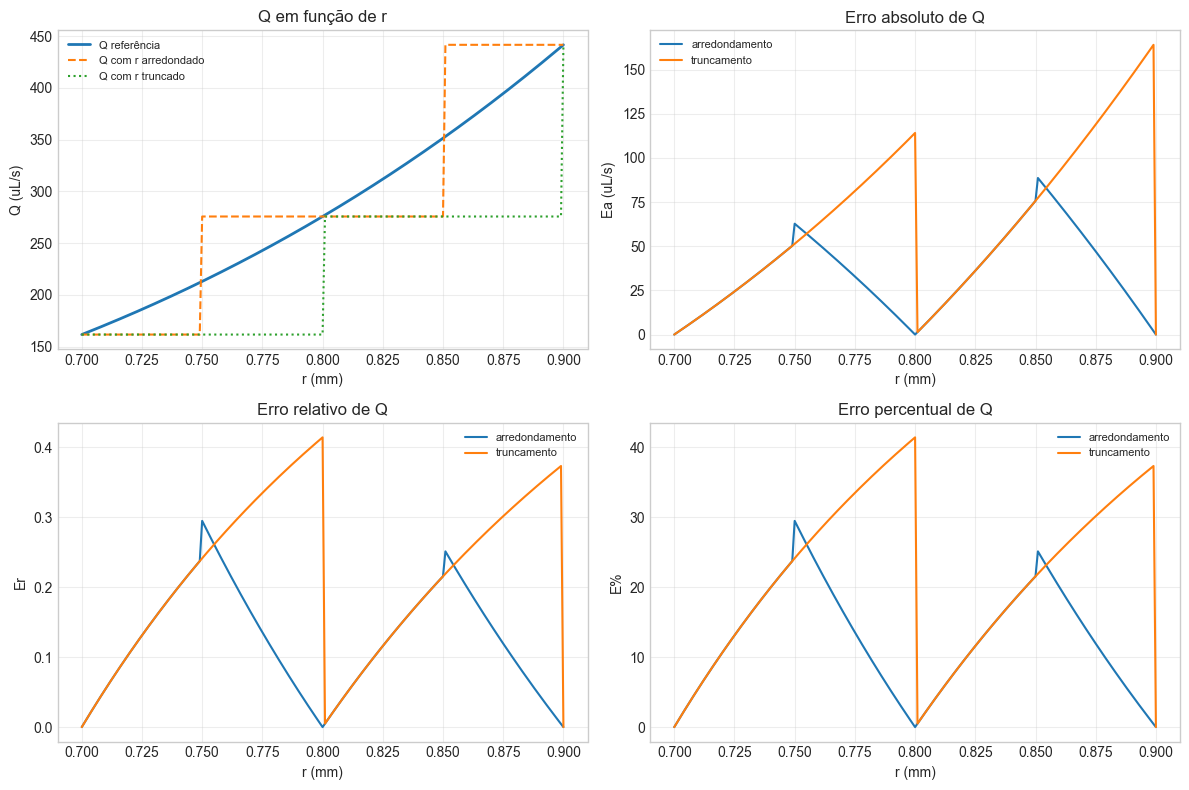

In [8]:
raios_mm = np.linspace(0.70, 0.90, 201)
Q_ref_raios = np.array([vazao_hagen_poiseuille(r_mm * 1e-3, L_c, mu_c, delta_p_c) for r_mm in raios_mm])
Q_round_raios = np.array([vazao_hagen_poiseuille(round(r_mm, 1) * 1e-3, L_c, mu_c, delta_p_c) for r_mm in raios_mm])
Q_trunc_raios = np.array([vazao_hagen_poiseuille(truncar(r_mm, 1) * 1e-3, L_c, mu_c, delta_p_c) for r_mm in raios_mm])

ea_round = np.abs(Q_ref_raios - Q_round_raios)
ea_trunc = np.abs(Q_ref_raios - Q_trunc_raios)
er_round = ea_round / np.abs(Q_ref_raios)
er_trunc = ea_trunc / np.abs(Q_ref_raios)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

axes[0].plot(raios_mm, Q_ref_raios * 1e9, label='Q referência', linewidth=2)
axes[0].plot(raios_mm, Q_round_raios * 1e9, label='Q com r arredondado', linestyle='--')
axes[0].plot(raios_mm, Q_trunc_raios * 1e9, label='Q com r truncado', linestyle=':')
axes[0].set_title('Q em função de r')
axes[0].set_xlabel('r (mm)')
axes[0].set_ylabel('Q (uL/s)')
axes[0].legend(fontsize=8)

axes[1].plot(raios_mm, ea_round * 1e9, label='arredondamento')
axes[1].plot(raios_mm, ea_trunc * 1e9, label='truncamento')
axes[1].set_title('Erro absoluto de Q')
axes[1].set_xlabel('r (mm)')
axes[1].set_ylabel('Ea (uL/s)')
axes[1].legend(fontsize=8)

axes[2].plot(raios_mm, er_round, label='arredondamento')
axes[2].plot(raios_mm, er_trunc, label='truncamento')
axes[2].set_title('Erro relativo de Q')
axes[2].set_xlabel('r (mm)')
axes[2].set_ylabel('Er')
axes[2].legend(fontsize=8)

axes[3].plot(raios_mm, 100 * er_round, label='arredondamento')
axes[3].plot(raios_mm, 100 * er_trunc, label='truncamento')
axes[3].set_title('Erro percentual de Q')
axes[3].set_xlabel('r (mm)')
axes[3].set_ylabel('E%')
axes[3].legend(fontsize=8)

for ax in axes:
    ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

**Resposta - Parte C.** O erro no raio é amplificado porque a vazão é proporcional a $r^4$. Pela aproximação linear, $\Delta Q/Q \approx 4\Delta r/r$. Portanto, um erro relativo pequeno no raio gera um erro relativo cerca de quatro vezes maior na vazão, além de possíveis assimetrias quando se calcula diretamente com $r+\Delta r$ ou $r-\Delta r$.

## 6. Parte D - escoamento em nanocateter

In [9]:
r_nm_d = 50.0
L_um_d = 10.0
mu_d = 3.5e-3
delta_p_d = 5000.0

r_m_d = r_nm_d * 1e-9
L_m_d = L_um_d * 1e-6
Q_ref_d = vazao_hagen_poiseuille(r_m_d, L_m_d, mu_d, delta_p_d)

print(f'Q(r = 50 nm) = {Q_ref_d:.6e} m³/s')
print(f'Q(r = 50 nm) = {Q_ref_d*1e18:.6f} aL/s')

Q(r = 50 nm) = 3.506242e-19 m³/s
Q(r = 50 nm) = 0.350624 aL/s


### D.1 Erro geométrico

In [10]:
delta_r_nm_values = np.arange(0.1, 5.0 + 0.1, 0.1)
linhas_d1 = []
for dr_nm in delta_r_nm_values:
    r_minus = (r_nm_d - dr_nm) * 1e-9
    r_plus = (r_nm_d + dr_nm) * 1e-9
    Q_minus = vazao_hagen_poiseuille(r_minus, L_m_d, mu_d, delta_p_d)
    Q_plus = vazao_hagen_poiseuille(r_plus, L_m_d, mu_d, delta_p_d)
    erro_max_abs = max(abs(Q_ref_d - Q_minus), abs(Q_plus - Q_ref_d))
    erro_max_rel = erro_max_abs / abs(Q_ref_d)
    linhas_d1.append({
        'Delta r (nm)': dr_nm,
        'r- (nm)': r_nm_d - dr_nm,
        'r+ (nm)': r_nm_d + dr_nm,
        'Q(r-) (m³/s)': Q_minus,
        'Q(r) (m³/s)': Q_ref_d,
        'Q(r+) (m³/s)': Q_plus,
        'Erro máximo absoluto (m³/s)': erro_max_abs,
        'Erro máximo relativo': erro_max_rel,
        'Erro máximo percentual (%)': 100 * erro_max_rel,
        'Aproximação linear percentual (%)': 100 * 4 * dr_nm / r_nm_d,
    })

tabela_d1 = pd.DataFrame(linhas_d1)
display(tabela_d1.head(10))
display(tabela_d1.tail(5))

,Delta r (nm),r- (nm),r+ (nm),Q(r-) (m³/s),Q(r) (m³/s),Q(r+) (m³/s),Erro máximo absoluto (m³/s),Erro máximo relativo,Erro máximo percentual (%),Aproximação linear percentual (%)
0,0.100000,49.900000,50.100000,3.478276e-19,3.506242e-19,3.534376e-19,2.813420e-21,0.008024,0.802403,0.800000
1,0.200000,49.800000,50.200000,3.450478e-19,3.506242e-19,3.562679e-19,5.643737e-21,0.016096,1.609626,1.600000
2,0.300000,49.700000,50.300000,3.422846e-19,3.506242e-19,3.591152e-19,8.491019e-21,0.024217,2.421687,2.400000
3,0.400000,49.600000,50.400000,3.395381e-19,3.506242e-19,3.619795e-19,1.135533e-20,0.032386,3.238605,3.200000
4,0.500000,49.500000,50.500000,3.368082e-19,3.506242e-19,3.648609e-19,1.423675e-20,0.040604,4.060401,4.000000
5,0.600000,49.400000,50.600000,3.340947e-19,3.506242e-19,3.677595e-19,1.713533e-20,0.048871,4.887093,4.800000
6,0.700000,49.300000,50.700000,3.313977e-19,3.506242e-19,3.706753e-19,2.005115e-20,0.057187,5.718701,5.600000
7,0.800000,49.200000,50.800000,3.287171e-19,3.506242e-19,3.736085e-19,2.298427e-20,0.065552,6.555245,6.400000
8,0.900000,49.100000,50.900000,3.260527e-19,3.506242e-19,3.765590e-19,2.593477e-20,0.073967,7.396743,7.200000
9,1.000000,49.000000,51.000000,3.234046e-19,3.506242e-19,3.795269e-19,2.890271e-20,0.082432,8.243216,8.000000


,Delta r (nm),r- (nm),r+ (nm),Q(r-) (m³/s),Q(r) (m³/s),Q(r+) (m³/s),Erro máximo absoluto (m³/s),Erro máximo relativo,Erro máximo percentual (%),Aproximação linear percentual (%)
45,4.600000,45.400000,54.600000,2.383336e-19,3.506242e-19,4.985772e-19,1.479530e-19,0.421970,42.197039,36.800000
46,4.700000,45.300000,54.700000,2.362407e-19,3.506242e-19,5.022398e-19,1.516156e-19,0.432416,43.241641,37.600000
47,4.800000,45.200000,54.800000,2.341616e-19,3.506242e-19,5.059226e-19,1.552984e-19,0.442920,44.291988,38.400000
48,4.900000,45.100000,54.900000,2.320962e-19,3.506242e-19,5.096256e-19,1.590014e-19,0.453481,45.348100,39.200000
49,5.000000,45.000000,55.000000,2.300445e-19,3.506242e-19,5.133489e-19,1.627247e-19,0.464100,46.410000,40.000000


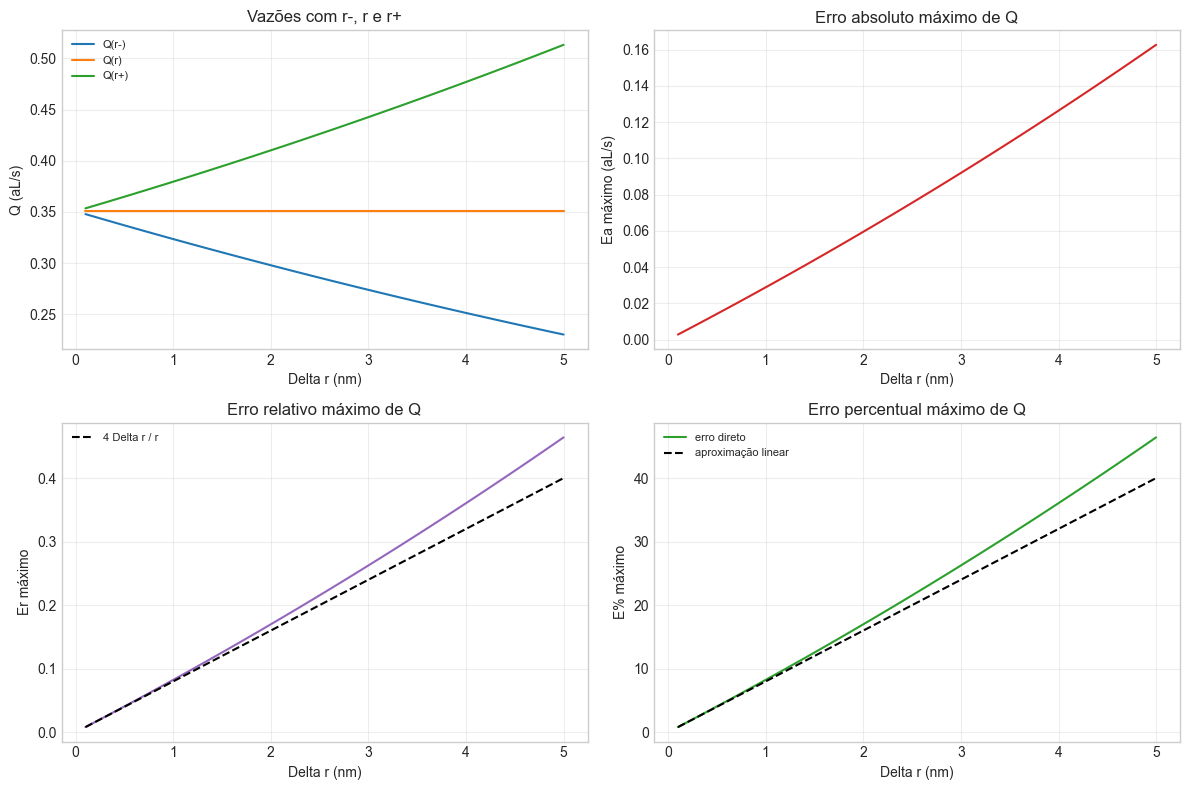

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

axes[0].plot(tabela_d1['Delta r (nm)'], tabela_d1['Q(r-) (m³/s)'] * 1e18, label='Q(r-)')
axes[0].plot(tabela_d1['Delta r (nm)'], tabela_d1['Q(r) (m³/s)'] * 1e18, label='Q(r)')
axes[0].plot(tabela_d1['Delta r (nm)'], tabela_d1['Q(r+) (m³/s)'] * 1e18, label='Q(r+)')
axes[0].set_title('Vazões com r-, r e r+')
axes[0].set_xlabel('Delta r (nm)')
axes[0].set_ylabel('Q (aL/s)')
axes[0].legend(fontsize=8)

axes[1].plot(tabela_d1['Delta r (nm)'], tabela_d1['Erro máximo absoluto (m³/s)'] * 1e18, color='tab:red')
axes[1].set_title('Erro absoluto máximo de Q')
axes[1].set_xlabel('Delta r (nm)')
axes[1].set_ylabel('Ea máximo (aL/s)')

axes[2].plot(tabela_d1['Delta r (nm)'], tabela_d1['Erro máximo relativo'], color='tab:purple')
axes[2].plot(tabela_d1['Delta r (nm)'], tabela_d1['Aproximação linear percentual (%)'] / 100, color='black', linestyle='--', label='4 Delta r / r')
axes[2].set_title('Erro relativo máximo de Q')
axes[2].set_xlabel('Delta r (nm)')
axes[2].set_ylabel('Er máximo')
axes[2].legend(fontsize=8)

axes[3].plot(tabela_d1['Delta r (nm)'], tabela_d1['Erro máximo percentual (%)'], color='tab:green', label='erro direto')
axes[3].plot(tabela_d1['Delta r (nm)'], tabela_d1['Aproximação linear percentual (%)'], color='black', linestyle='--', label='aproximação linear')
axes[3].set_title('Erro percentual máximo de Q')
axes[3].set_xlabel('Delta r (nm)')
axes[3].set_ylabel('E% máximo')
axes[3].legend(fontsize=8)

for ax in axes:
    ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

A aproximação linear $\Delta Q/Q \approx 4\Delta r/r$ acompanha bem o erro direto para pequenas variações de raio. À medida que $\Delta r$ cresce, a diferença aumenta porque o cálculo exato contém termos de ordem superior associados à potência quarta. Além disso, o aumento de vazão para $r+\Delta r$ é maior do que a redução para $r-\Delta r$, pois a função $r^4$ é não linear.

### D.2 Precisão computacional

In [12]:
def vazao_numpy(raio_m, comprimento_m, viscosidade_pa_s, delta_p_pa, dtype):
    raio = dtype(raio_m)
    comprimento = dtype(comprimento_m)
    viscosidade = dtype(viscosidade_pa_s)
    delta_p = dtype(delta_p_pa)
    pi = dtype(np.pi)
    r4 = raio ** dtype(4)
    Q = pi * r4 * delta_p / (dtype(8) * viscosidade * comprimento)
    return r4, Q

r4_32, Q_32 = vazao_numpy(r_m_d, L_m_d, mu_d, delta_p_d, np.float32)
r4_64, Q_64 = vazao_numpy(r_m_d, L_m_d, mu_d, delta_p_d, np.float64)

tabela_float = pd.DataFrame({
    'tipo': ['float32', 'float64'],
    'r^4': [float(r4_32), float(r4_64)],
    'Q (m³/s)': [float(Q_32), float(Q_64)],
    'eps': [np.finfo(np.float32).eps, np.finfo(np.float64).eps],
})

dif_abs_float = abs(float(Q_64) - float(Q_32))
dif_rel_float = dif_abs_float / abs(float(Q_64))

display(tabela_float)
print(f'Diferença absoluta entre Q float64 e Q float32: {dif_abs_float:.6e} m³/s')
print(f'Diferença relativa entre Q float64 e Q float32: {dif_rel_float:.6e}')

,tipo,r^4,Q (m³/s),eps
0,float32,6.250000e-30,3.506242e-19,1.192093e-07
1,float64,6.250000e-30,3.506242e-19,2.220446e-16


Diferença absoluta entre Q float64 e Q float32: 5.228628e-26 m³/s
Diferença relativa entre Q float64 e Q float32: 1.491234e-07


In [13]:
razoes = np.array([10.0**(-k) for k in range(1, 15)])
linhas_cancelamento = []
for eps_rel in razoes:
    dr = eps_rel * r_m_d
    Q_base = vazao_hagen_poiseuille(r_m_d, L_m_d, mu_d, delta_p_d)
    Q_var = vazao_hagen_poiseuille(r_m_d + dr, L_m_d, mu_d, delta_p_d)
    delta1 = (Q_var - Q_base) / Q_base
    delta2 = (1 + dr / r_m_d)**4 - 1
    diff = abs(delta1 - delta2)
    linhas_cancelamento.append({
        'Delta r / r': eps_rel,
        'delta1 via subtração de Q': delta1,
        'delta2 fórmula adimensional': delta2,
        'diferença absoluta': diff,
        'diferença relativa': diff / abs(delta2) if delta2 != 0 else np.nan,
    })

tabela_cancelamento = pd.DataFrame(linhas_cancelamento)
display(tabela_cancelamento)

,Delta r / r,delta1 via subtração de Q,delta2 fórmula adimensional,diferença absoluta,diferença relativa
0,0.100000,0.464100,0.464100,2.220446e-16,4.784413e-16
1,0.010000,0.040604,0.040604,1.040834e-16,2.563378e-15
2,0.001000,0.004006,0.004006,2.211772e-16,5.521144e-14
3,1.000000e-04,4.000600e-04,4.000600e-04,1.241411e-16,3.103063e-13
4,1.000000e-05,4.000060e-05,4.000060e-05,2.265440e-16,5.663516e-12
5,1.000000e-06,4.000006e-06,4.000006e-06,5.357585e-16,1.339394e-10
6,1.000000e-07,4.000001e-07,4.000001e-07,1.866356e-16,4.665890e-10
7,1.000000e-08,4.000000e-08,4.000000e-08,3.174459e-16,7.936148e-09
8,1.000000e-09,4.000000e-09,4.000000e-09,3.667706e-16,9.169265e-08
9,1.000000e-10,4.000003e-10,4.000000e-10,2.791625e-16,6.979061e-07


Para `float32`, a precisão de máquina é muito maior do que para `float64`, então pequenas diferenças relativas são mais difíceis de representar. Na comparação de $\delta_1$ e $\delta_2$, a forma $\delta_1 = [Q(r+\Delta r)-Q(r)]/Q(r)$ pode sofrer perda de significância quando $\Delta r/r$ fica muito pequeno, pois subtrai duas vazões quase iguais. A forma adimensional $\delta_2=(1+\Delta r/r)^4-1$ evita parte do problema por trabalhar diretamente com a variação relativa.

### D.3 Fenômeno físico

Em escala nanométrica, a redução do tamanho do canal aumenta a razão superfície/volume. Com isso, os efeitos viscosos e as interações próximas à parede passam a ter peso maior no escoamento. O modelo de Hagen-Poiseuille é útil como aproximação didática, mas assume hipóteses idealizadas, como fluido contínuo, escoamento laminar plenamente desenvolvido, tubo cilíndrico rígido e condições simples na parede. Portanto, um resultado com muitas casas decimais pode ser aritmeticamente preciso e, ainda assim, fisicamente inadequado se o modelo não representar os fenômenos dominantes na escala analisada.

## 7. Parte E - síntese visual em PNG

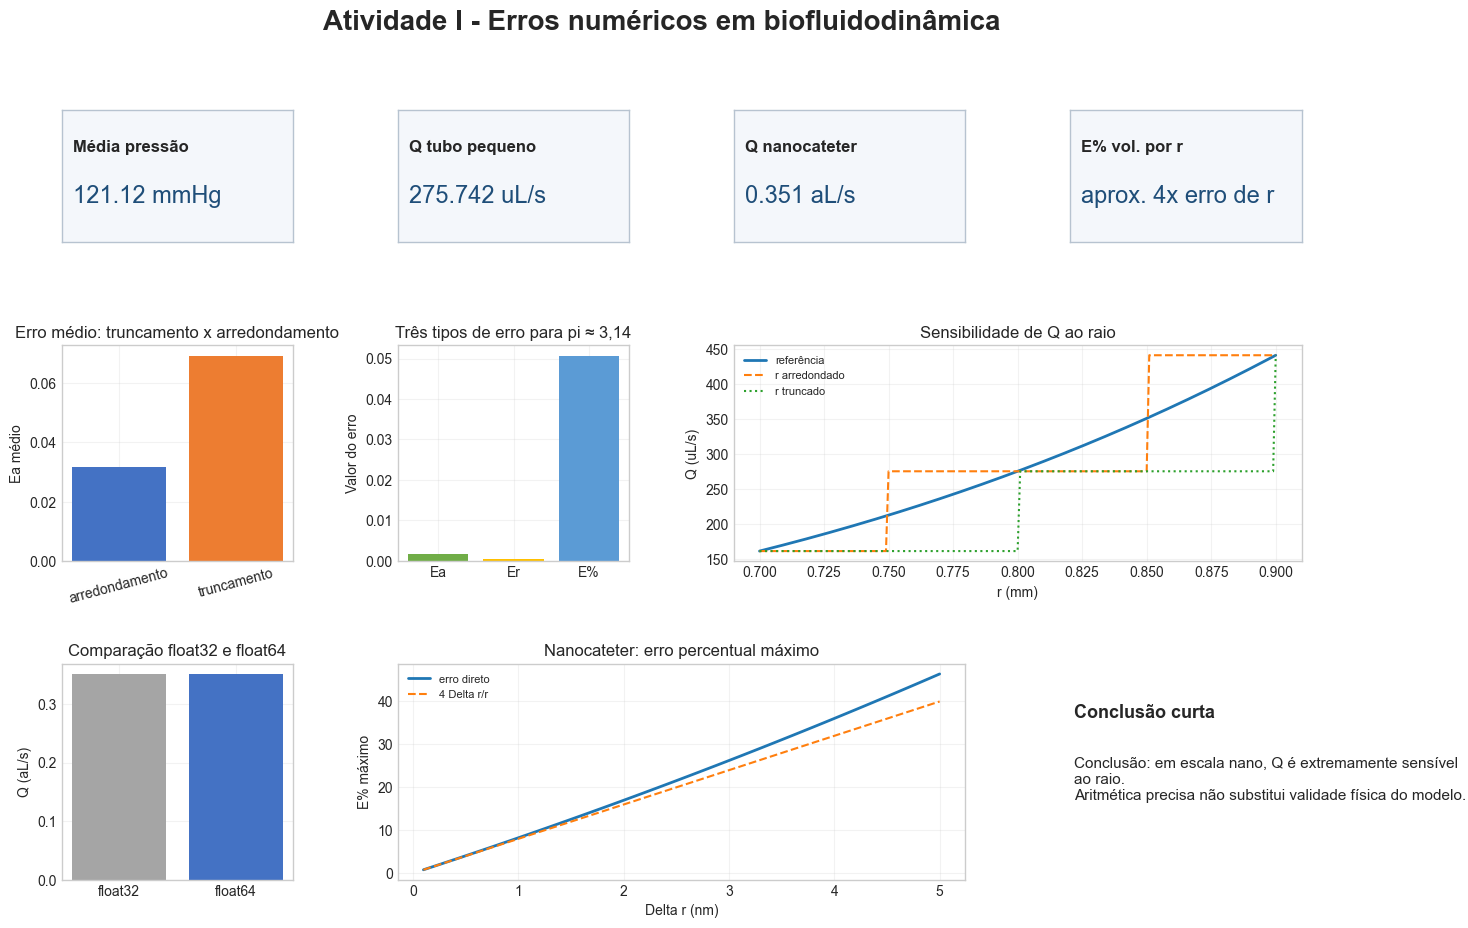

PNG salvo em: figuras/quadro_resultados.png


In [14]:
fig = plt.figure(figsize=(16, 10), dpi=100)
grid = fig.add_gridspec(3, 4, height_ratios=[0.8, 1.3, 1.3], hspace=0.55, wspace=0.45)
fig.suptitle('Atividade I - Erros numéricos em biofluidodinâmica', fontsize=20, fontweight='bold')

card_data = [
    ('Média pressão', f'{media_referencia_pressao:.2f} mmHg'),
    ('Q tubo pequeno', f'{Q_ref_c*1e9:.3f} uL/s'),
    ('Q nanocateter', f'{Q_ref_d*1e18:.3f} aL/s'),
    ('E% vol. por r', 'aprox. 4x erro de r'),
]
for i, (titulo, valor) in enumerate(card_data):
    ax = fig.add_subplot(grid[0, i])
    ax.set_facecolor('#f4f7fb')
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#b7c3d0')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(0.05, 0.68, titulo, fontsize=12, fontweight='bold', transform=ax.transAxes)
    ax.text(0.05, 0.30, valor, fontsize=17, color='#1f4e79', transform=ax.transAxes)

ax = fig.add_subplot(grid[1, 0])
resumo_a = tabela_a.groupby('método')['Ea'].mean().reset_index()
ax.bar(resumo_a['método'], resumo_a['Ea'], color=['#4472c4', '#ed7d31'])
ax.set_title('Erro médio: truncamento x arredondamento')
ax.set_ylabel('Ea médio')
ax.tick_params(axis='x', rotation=15)

ax = fig.add_subplot(grid[1, 1])
erros_pi = pd.DataFrame([
    {'tipo': 'Ea', 'valor': calcular_erros(math.pi, 3.14)[0]},
    {'tipo': 'Er', 'valor': calcular_erros(math.pi, 3.14)[1]},
    {'tipo': 'E%', 'valor': calcular_erros(math.pi, 3.14)[2]},
])
ax.bar(erros_pi['tipo'], erros_pi['valor'], color=['#70ad47', '#ffc000', '#5b9bd5'])
ax.set_title('Três tipos de erro para pi ≈ 3,14')
ax.set_ylabel('Valor do erro')

ax = fig.add_subplot(grid[1, 2:])
ax.plot(raios_mm, Q_ref_raios * 1e9, linewidth=2, label='referência')
ax.plot(raios_mm, Q_round_raios * 1e9, linestyle='--', label='r arredondado')
ax.plot(raios_mm, Q_trunc_raios * 1e9, linestyle=':', label='r truncado')
ax.set_title('Sensibilidade de Q ao raio')
ax.set_xlabel('r (mm)')
ax.set_ylabel('Q (uL/s)')
ax.legend(fontsize=8)

ax = fig.add_subplot(grid[2, 0])
ax.bar(tabela_float['tipo'], tabela_float['Q (m³/s)'] * 1e18, color=['#a5a5a5', '#4472c4'])
ax.set_title('Comparação float32 e float64')
ax.set_ylabel('Q (aL/s)')

ax = fig.add_subplot(grid[2, 1:3])
ax.plot(tabela_d1['Delta r (nm)'], tabela_d1['Erro máximo percentual (%)'], label='erro direto', linewidth=2)
ax.plot(tabela_d1['Delta r (nm)'], tabela_d1['Aproximação linear percentual (%)'], linestyle='--', label='4 Delta r/r')
ax.set_title('Nanocateter: erro percentual máximo')
ax.set_xlabel('Delta r (nm)')
ax.set_ylabel('E% máximo')
ax.legend(fontsize=8)

ax = fig.add_subplot(grid[2, 3])
ax.axis('off')
conclusao_curta = (
    'Conclusão: em escala nano, Q é extremamente sensível ao raio.\n'
    'Aritmética precisa não substitui validade física do modelo.'
)
ax.text(0.02, 0.75, 'Conclusão curta', fontsize=13, fontweight='bold')
ax.text(0.02, 0.38, conclusao_curta, fontsize=11, wrap=True)

for ax in fig.axes:
    ax.grid(True, alpha=0.25)

png_path = output_dir / 'quadro_unico_resultados.png'
plt.savefig(png_path, dpi=100)
plt.show()
print(f'PNG salvo em: {png_path.resolve()}')

## 8. GIF demonstrativo

GIF salvo em: figuras/nanocateter_vazao_raio.gif


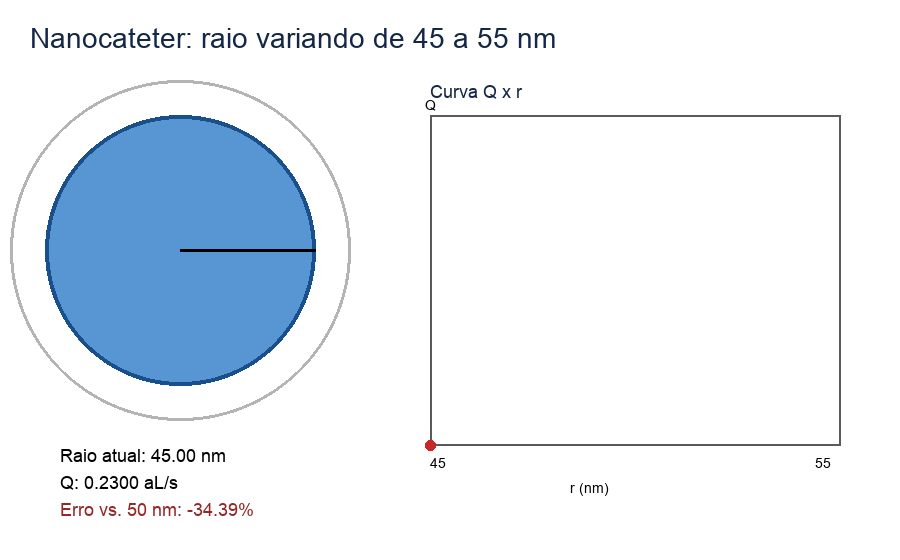

In [15]:
def criar_frame_gif(frame_index, total_frames, largura=900, altura=560):
    raio_nm = 45 + 10 * frame_index / (total_frames - 1)
    raio_m = raio_nm * 1e-9
    Q_atual = vazao_hagen_poiseuille(raio_m, L_m_d, mu_d, delta_p_d)
    erro_percentual = 100 * (Q_atual - Q_ref_d) / Q_ref_d

    imagem = Image.new('RGB', (largura, altura), 'white')
    draw = ImageDraw.Draw(imagem)

    try:
        fonte_titulo = ImageFont.truetype('Arial.ttf', 28)
        fonte = ImageFont.truetype('Arial.ttf', 18)
        fonte_pequena = ImageFont.truetype('Arial.ttf', 14)
    except Exception:
        fonte_titulo = fonte = fonte_pequena = None

    draw.text((30, 22), 'Nanocateter: raio variando de 45 a 55 nm', fill=(20, 40, 70), font=fonte_titulo)

    # Seção transversal do canal.
    centro = (180, 250)
    escala = 3.0
    raio_px = int(raio_nm * escala)
    draw.ellipse((centro[0]-170, centro[1]-170, centro[0]+170, centro[1]+170), outline=(180, 180, 180), width=3)
    draw.ellipse((centro[0]-raio_px, centro[1]-raio_px, centro[0]+raio_px, centro[1]+raio_px), fill=(87, 150, 210), outline=(25, 80, 140), width=4)
    draw.line((centro[0], centro[1], centro[0]+raio_px, centro[1]), fill=(0, 0, 0), width=3)
    draw.text((60, 445), f'Raio atual: {raio_nm:.2f} nm', fill=(0, 0, 0), font=fonte)
    draw.text((60, 472), f'Q: {Q_atual*1e18:.4f} aL/s', fill=(0, 0, 0), font=fonte)
    draw.text((60, 499), f'Erro vs. 50 nm: {erro_percentual:+.2f}%', fill=(150, 40, 40), font=fonte)

    # Curva Q x r construída progressivamente.
    plot_x0, plot_y0 = 430, 115
    plot_w, plot_h = 410, 330
    draw.rectangle((plot_x0, plot_y0, plot_x0+plot_w, plot_y0+plot_h), outline=(90, 90, 90), width=2)
    draw.text((plot_x0, plot_y0 - 34), 'Curva Q x r', fill=(20, 40, 70), font=fonte)
    draw.text((plot_x0 + 140, plot_y0 + plot_h + 35), 'r (nm)', fill=(0, 0, 0), font=fonte_pequena)
    draw.text((plot_x0 - 5, plot_y0 - 18), 'Q', fill=(0, 0, 0), font=fonte_pequena)

    r_curve = np.linspace(45, raio_nm, frame_index + 1)
    q_curve = np.array([vazao_hagen_poiseuille(rv * 1e-9, L_m_d, mu_d, delta_p_d) for rv in r_curve]) * 1e18
    r_all = np.linspace(45, 55, 200)
    q_all = np.array([vazao_hagen_poiseuille(rv * 1e-9, L_m_d, mu_d, delta_p_d) for rv in r_all]) * 1e18
    q_min, q_max = q_all.min(), q_all.max()

    pontos = []
    for rv, qv in zip(r_curve, q_curve):
        px = plot_x0 + int((rv - 45) / 10 * plot_w)
        py = plot_y0 + plot_h - int((qv - q_min) / (q_max - q_min) * plot_h)
        pontos.append((px, py))
    if len(pontos) > 1:
        draw.line(pontos, fill=(87, 150, 210), width=4)
    if pontos:
        px, py = pontos[-1]
        draw.ellipse((px-5, py-5, px+5, py+5), fill=(200, 40, 40))

    draw.text((plot_x0, plot_y0 + plot_h + 10), '45', fill=(0, 0, 0), font=fonte_pequena)
    draw.text((plot_x0 + plot_w - 25, plot_y0 + plot_h + 10), '55', fill=(0, 0, 0), font=fonte_pequena)
    return imagem

num_frames = 40
frames = [criar_frame_gif(i, num_frames) for i in range(num_frames)]
gif_path = output_dir / 'nanocateter_vazao_raio.gif'
frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=120, loop=0)
print(f'GIF salvo em: {gif_path.resolve()}')
display(IPythonImage(filename=str(gif_path)))

## 9. Conclusão final

Os resultados mostram que a escolha entre truncamento e arredondamento afeta diretamente a qualidade da aproximação, sendo o arredondamento geralmente mais fiel por escolher o valor mais próximo na precisão desejada. Nas medidas de pressão, os erros da média foram pequenos ao usar valores inteiros, mas a variabilidade e a forma da distribuição foram modificadas, o que mostra que a simplificação pode ser aceitável para uma média aproximada, mas não para uma análise detalhada. Na vazão calculada pela relação de Hagen-Poiseuille, o raio é a variável mais sensível porque aparece elevado à quarta potência, fazendo com que pequenas incertezas geométricas sejam amplificadas. No caso do nanocateter, essa sensibilidade é ainda mais importante, e a comparação entre `float32` e `float64` reforça que precisão computacional e validade física do modelo são conceitos diferentes. Os gráficos, o quadro-síntese e o GIF ajudam a comunicar visualmente como os erros crescem e por que decisões numéricas em engenharia devem considerar unidades, escala, propagação de incertezas e hipóteses físicas.